# Module 09: Same soil, different winters

*The code behind GEOS 212: Water in the West, Boise State University*

In Module 09 we followed water into the soil: infiltration, storage, and drainage. In the Boise River basin, the timing of that water depends on the snowpack. When precipitation falls as snow, it waits on top of the ground until spring. When it falls as rain, it soaks in right away.

So what did the warm snow drought of WY2026 do to soil moisture? We'll use NASA's **SMAP** (Soil Moisture Active Passive) satellite to compare WY2023 (snowy) and WY2026 (snow drought) at two places: the high mountains at Banner Summit and the Dry Creek foothills just above Boise.

**Where are we in the water year?** In the *soil*.

> **New to Jupyter?** Click a gray code cell and press **Shift + Enter** to run it. Run the cells in order.

## 1. Setup

In [1]:
import io
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests

# The GEOS 212 "water" colors, so these plots match the lecture slides
INK, DEEP, RIVER, GLACIER, OCHRE, BASALT, MIST = (
    "#14303F", "#0E4D64", "#137C8B", "#4FB0C6", "#D9822B", "#5B6770", "#EAF4F4")
plt.rcParams.update({"figure.dpi": 110, "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False})

# If a live download fails (no internet, or an agency changes its website),
# we fall back to a copy of the data saved in this repository.
DATA_DIR = Path("../data")
DATA_URL = "https://raw.githubusercontent.com/LejoFlores/geos212-code/main/data/"

def fetch_text(url, cache_name):
    """Download text from `url`. Save a copy as data/<cache_name>.
    If the download fails, use the saved copy instead."""
    try:
        r = requests.get(url, timeout=60)
        r.raise_for_status()
        text = r.text
        if DATA_DIR.exists():
            (DATA_DIR / cache_name).write_text(text)
        print(f"Downloaded live data -> {cache_name}")
    except Exception as err:
        print(f"Live download failed ({type(err).__name__}); using saved copy of {cache_name}")
        local = DATA_DIR / cache_name
        text = local.read_text() if local.exists() else requests.get(DATA_URL + cache_name, timeout=60).text
    return text

In [2]:
def water_year(dates):
    """Water year: Oct 1 2025 - Sep 30 2026 is water year 2026."""
    return dates.year + (dates.month >= 10)

def wy_axis_date(dates):
    """Map every date onto one shared 'generic' water year (Oct 2000 - Sep 2001),
    so different years can be drawn on the same x-axis."""
    return pd.to_datetime([pd.Timestamp(2000 if d.month >= 10 else 2001, d.month, min(d.day, 28) if d.month == 2 else d.day)
                           for d in dates])

def month_axis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

## 2. About the data: SMAP Level 4

SMAP, launched in 2015, carries a microwave **radiometer** that measures the natural microwave glow of the land surface. Wet soil glows less than dry soil, so the brightness tells us how wet the top few centimeters are. (SMAP also carried a radar, but it failed in July 2015.)

The satellite only sees the top ~5 cm, and only every 2-3 days. The **Level 4** product fixes both problems by feeding the satellite measurements into a NASA land-surface model, which estimates water in the top **1 meter** (the *root zone*) every 3 hours on a 9 km grid. Under deep snow or frozen ground, the satellite can't see the soil, so those values come mostly from the model.

Downloading SMAP requires a free NASA Earthdata account, so we saved daily root-zone values for three 9 km grid cells: Banner Summit, the Dry Creek foothills, and the Boise valley. Values are *volumetric* soil moisture: the fraction of the soil volume that is water.

In [3]:
name = "smap_l4_boise_points_wy2023_wy2026.csv"
source = DATA_DIR / name if (DATA_DIR / name).exists() else DATA_URL + name
sm = pd.read_csv(source, parse_dates=["t"]).replace(-9999, np.nan)
sm["wy"] = water_year(sm.t.dt)
sm["root_pct"] = 100 * sm.root          # fraction -> percent by volume
print(sm.site.unique(), "   water years:", sorted(sm.wy.unique()))
sm.head()

<StringArray>
['Dry Creek foothills', 'Banner Summit', 'Boise valley']
Length: 3, dtype: str    water years: [np.int32(2023), np.int32(2026)]


,t,site,surf,root,pctl,wy,root_pct
0,2022-10-01,Dry Creek foothills,0.048503,0.048925,NaN,2023,4.892515
1,2022-10-01,Banner Summit,0.056117,0.066473,NaN,2023,6.647276
2,2022-10-01,Boise valley,0.082896,0.160894,NaN,2023,16.089416
3,2022-10-02,Dry Creek foothills,0.034579,0.047724,NaN,2023,4.772405
4,2022-10-02,Banner Summit,0.055301,0.066187,NaN,2023,6.618718


## 3. Comparing the two winters

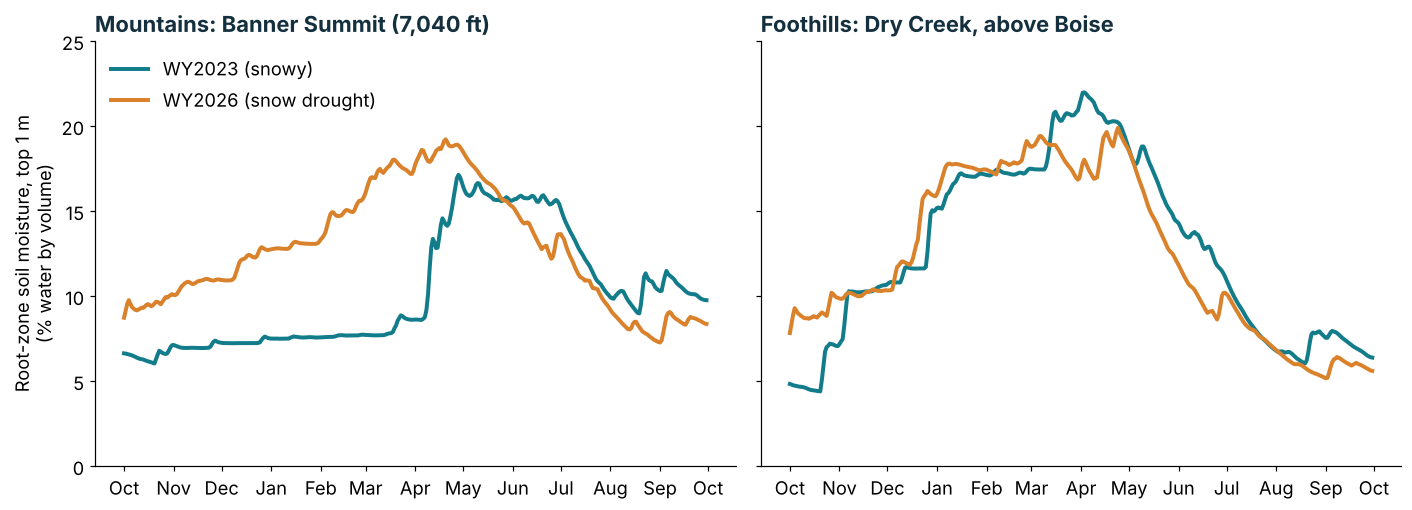

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, site, title in [(axs[0], "Banner Summit", "Mountains: Banner Summit (7,040 ft)"),
                        (axs[1], "Dry Creek foothills", "Foothills: Dry Creek, above Boise")]:
    for wy, color, label in [(2023, RIVER, "WY2023 (snowy)"), (2026, OCHRE, "WY2026 (snow drought)")]:
        d = sm[(sm.site == site) & (sm.wy == wy)].sort_values("t")
        smooth = d.root_pct.rolling(3, center=True, min_periods=1).mean()   # 3-day running mean
        ax.plot(wy_axis_date(d.t), smooth, color=color, lw=2.6, label=label)
    month_axis(ax)
    ax.set_ylim(0, 25)
    ax.set_title(title, loc="left", fontweight="bold", color=INK)
axs[0].set_ylabel("Root-zone soil moisture, top 1 m\n(% water by volume)")
axs[0].legend(frameon=False, loc="upper left")
plt.tight_layout()

Now some numbers: winter (Oct-Feb) average, the spring peak, the late-summer (Jul-Sep) average, and the first day after the peak that the soil dropped below 10%.

In [5]:
rows = []
for site in ["Banner Summit", "Dry Creek foothills"]:
    for wy in [2023, 2026]:
        s = sm[(sm.site == site) & (sm.wy == wy)].set_index("t").root_pct
        peak_day = s.idxmax()
        after = s[peak_day:]
        dry = after[after < 10]
        rows.append({"site": site, "water year": wy,
                     "Oct-Feb mean (%)": round(s[:f"{wy}-02-28"].mean(), 1),
                     "peak (%)": round(s.max(), 1), "peak date": f"{peak_day:%b %d}",
                     "first day < 10% after peak": f"{dry.index[0]:%b %d}" if len(dry) else "never",
                     "Jul-Sep mean (%)": round(s[f"{wy}-07-01":].mean(), 1)})
pd.DataFrame(rows)

,site,water year,Oct-Feb mean (%),peak (%),peak date,first day < 10% after peak,Jul-Sep mean (%)
0,Banner Summit,2023,7.2,17.2,Apr 28,Aug 01,11.0
1,Banner Summit,2026,12.0,19.4,Apr 20,Jul 26,9.3
2,Dry Creek foothills,2023,12.1,22.1,Apr 03,Jul 06,7.6
3,Dry Creek foothills,2026,13.5,20.2,Apr 23,Jun 14,6.7


**What happened?**

* **Mountains.** In the snowy year, the soil at Banner sat at about 7% all winter under the snowpack: the water was locked up in the snow, and the ground was likely frozen. When the snow melted in late April, the soil filled up in a few weeks. In WY2026, rain and midwinter melt soaked in from November on, so the soil was much wetter all winter.
* **Foothills.** Low elevations get rain in winter either way, so the winters look similar. The difference is spring: in WY2026 the soil dried below 10% about three weeks sooner. That's three weeks less green-up for plants, and three more weeks of fire season.

Water that soaks in early can drain to groundwater or streams early, or be used by plants early. Either way, it isn't there in July, which is when the snowpack used to deliver it.

## 4. Your turn

1. **The valley.** Add the "Boise valley" cell to the plot. It's mostly irrigated farmland and suburbs. Does it follow the snow, the rain, or something else? (Hint: when do the canals turn on?)
2. **Surface vs. root zone.** The file also has `surf`, the top 5 cm. Plot `surf` and `root` together for Banner in WY2026. Which responds faster to a storm? Why?
3. **A head start?** WY2023 began after a dry 2022. Compare the October 1 soil moisture at Banner in both years. How much of the winter difference might be just the starting point?
4. **Water balance.** If the root zone at Banner went from 7% to 17% in a few weeks of snowmelt, how many millimeters of water entered the top 1 m of soil? (Hint: 1% of 1 m = 10 mm.)

### Why code?
A satellite, a land-surface model and a few dozen lines of pandas let us ask how a warm winter changed the timing of water in the soil at any 9 km spot on Earth. Swapping in your hometown takes one edit to the download.

---
*Data: NASA SMAP L4 Global 3-hourly 9 km EASE-Grid Surface and Root Zone Soil Moisture, Version 8 (SPL4SMGP, doi:10.5067/T5RUATAQREF8), NSIDC DAAC; 10:30 UTC value each day, WY2023 and WY2026.*